In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Hyperparameters
BATCH_SIZE = 128
LEARNING_RATE = 0.001
EPOCHS = 30

print("Device:", device)

Device: cuda


In [ ]:
import sys
import os

sys.path.append(os.path.abspath(".."))

from models.vanilla_autoencoder import VanillaAutoencoder

In [4]:
model = VanillaAutoencoder(latent_dim=64).to(device)

criterion = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print(model)

VanillaAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=64, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)


In [5]:
def train_autoencoder(model, train_loader, val_loader, epochs):
    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        # Training
        model.train()
        running_loss = 0.0

        for images, _ in train_loader:
            images = images.to(device)

            optimizer.zero_grad()

            reconstructed = model(images)
            loss = criterion(reconstructed, images)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        train_loss = running_loss / len(train_loader)
        train_losses.append(train_loss)

        # Validation
        model.eval()
        val_loss = 0.0

        with torch.no_grad():
            for images, _ in val_loader:
                images = images.to(device)

                reconstructed = model(images)
                loss = criterion(reconstructed, images)

                val_loss += loss.item()

        val_loss = val_loss / len(val_loader)
        val_losses.append(val_loss)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {train_loss:.6f} "
            f"Val Loss: {val_loss:.6f}"
        )

    return train_losses, val_losses

In [6]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, ConcatDataset, random_split

# Transform
transform = transforms.ToTensor()

# Load Fashion-MNIST
original_train = datasets.FashionMNIST(
    root="../data",
    train=True,
    download=True,
    transform=transform
)

original_test = datasets.FashionMNIST(
    root="../data",
    train=False,
    download=True,
    transform=transform
)

# Combine datasets
full_dataset = ConcatDataset([
    original_train,
    original_test
])

# Split 80:10:10
total_size = len(full_dataset)

train_size = int(0.8 * total_size)
val_size = int(0.1 * total_size)
test_size = total_size - train_size - val_size

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=generator
)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Training: 56000
Validation: 7000
Testing: 7000


In [7]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 438
Validation batches: 55
Testing batches: 55


In [8]:
train_losses, val_losses = train_autoencoder(
    model,
    train_loader,
    val_loader,
    EPOCHS
)

Epoch [1/30] Train Loss: 0.032235 Val Loss: 0.018916
Epoch [2/30] Train Loss: 0.016637 Val Loss: 0.015273
Epoch [3/30] Train Loss: 0.014018 Val Loss: 0.013236
Epoch [4/30] Train Loss: 0.012402 Val Loss: 0.012030
Epoch [5/30] Train Loss: 0.011379 Val Loss: 0.011620
Epoch [6/30] Train Loss: 0.010620 Val Loss: 0.010469
Epoch [7/30] Train Loss: 0.010029 Val Loss: 0.010239
Epoch [8/30] Train Loss: 0.009546 Val Loss: 0.009586
Epoch [9/30] Train Loss: 0.009136 Val Loss: 0.009172
Epoch [10/30] Train Loss: 0.008776 Val Loss: 0.009016
Epoch [11/30] Train Loss: 0.008464 Val Loss: 0.008592
Epoch [12/30] Train Loss: 0.008201 Val Loss: 0.008317
Epoch [13/30] Train Loss: 0.007956 Val Loss: 0.008188
Epoch [14/30] Train Loss: 0.007751 Val Loss: 0.007924
Epoch [15/30] Train Loss: 0.007583 Val Loss: 0.007828
Epoch [16/30] Train Loss: 0.007424 Val Loss: 0.007654
Epoch [17/30] Train Loss: 0.007276 Val Loss: 0.007473
Epoch [18/30] Train Loss: 0.007148 Val Loss: 0.007383
Epoch [19/30] Train Loss: 0.007037 Va

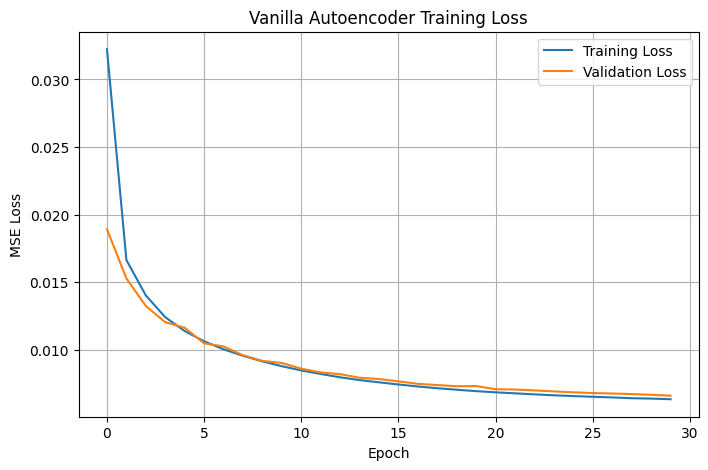

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Vanilla Autoencoder Training Loss")

plt.legend()
plt.grid(True)
plt.show()

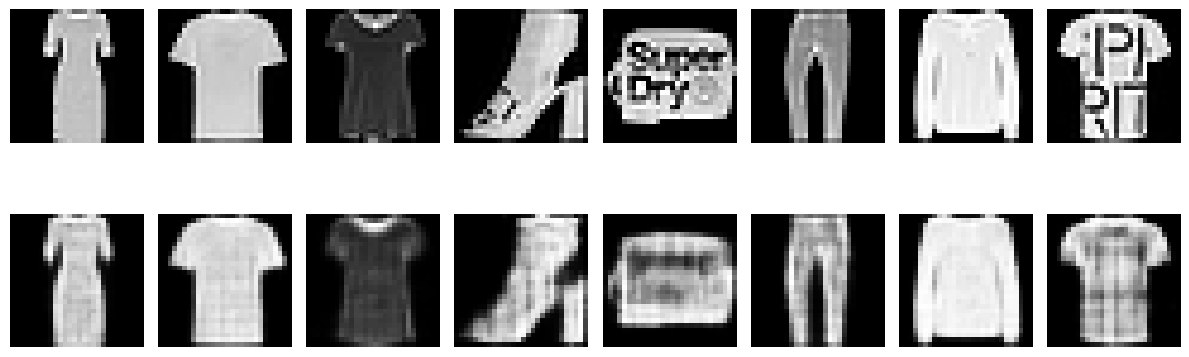

In [10]:
model.eval()

images, labels = next(iter(test_loader))
images = images.to(device)

with torch.no_grad():
    reconstructed = model(images)

plt.figure(figsize=(12, 5))

for i in range(8):
    # Original
    plt.subplot(2, 8, i + 1)
    plt.imshow(images[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Original")

    # Reconstructed
    plt.subplot(2, 8, i + 9)
    plt.imshow(reconstructed[i].cpu().squeeze(), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Reconstructed")

plt.tight_layout()
plt.show()

In [11]:
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr
import numpy as np

In [12]:
model.eval()

mse_total = 0
psnr_total = 0
ssim_total = 0
total_images = 0

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(device)

        reconstructed = model(images)

        original_np = images.cpu().numpy()
        reconstructed_np = reconstructed.cpu().numpy()

        for i in range(len(images)):
            original = original_np[i].squeeze()
            generated = reconstructed_np[i].squeeze()

            mse_total += np.mean((original - generated) ** 2)

            psnr_total += psnr(
                original, generated, data_range=1.0
            )

            ssim_total += ssim(
                original, generated, data_range=1.0
            )

            total_images += 1

print("MSE:", mse_total / total_images)
print("PSNR:", psnr_total / total_images)
print("SSIM:", ssim_total / total_images)

MSE: 0.0065666809713833835
PSNR: 22.95879791816599
SSIM: 0.8270135127315491


In [13]:
import os
import torch

# Create checkpoint directory
os.makedirs("../results/checkpoints", exist_ok=True)

# Save model weights
torch.save(
    model.state_dict(),
    "../results/checkpoints/vanilla_autoencoder.pth"
)

print("Vanilla Autoencoder saved successfully!")

Vanilla Autoencoder saved successfully!
